In [1]:
import sys

print(sys.executable)

/Users/tankarajjoshi/anaconda3/envs/fraud-mining/bin/python3.11


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
#Load and clean the dataset

In [4]:
# Load the original dataset
df = pd.read_csv("../data/raw/creditcard.csv")

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Display dataset information
print("Original transactions:", len(df))
print("Duplicates removed:", len(df) - len(df_clean))
print("Cleaned transactions:", len(df_clean))

print("\nClass distribution:")
print(df_clean["Class"].value_counts())


Original transactions: 284807
Duplicates removed: 1081
Cleaned transactions: 283726

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [5]:
#Split the dataset (80/10/10)

In [6]:
# Separate features and target
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

# Split into 80% training and 20% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Split temporary data into 10% validation and 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

print("Training:", X_train.shape, "| Fraud:", y_train.sum())
print("Validation:", X_val.shape, "| Fraud:", y_val.sum())
print("Test:", X_test.shape, "| Fraud:", y_test.sum())

Training: (226980, 30) | Fraud: 378
Validation: (28373, 30) | Fraud: 48
Test: (28373, 30) | Fraud: 47


In [7]:
#Feature Standardization

In [8]:
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Training: (226980, 30)
Validation: (28373, 30)
Test: (28373, 30)


In [9]:
#Train Standard and Class-Weighted Logistic Regression

In [10]:
# Standard Logistic Regression
standard_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

standard_model.fit(X_train_scaled, y_train)

# Class-Weighted Logistic Regression
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_model.fit(X_train_scaled, y_train)

print("Standard Logistic Regression trained successfully.")
print("Class-Weighted Logistic Regression trained successfully.")

Standard Logistic Regression trained successfully.
Class-Weighted Logistic Regression trained successfully.


In [11]:
#Generate validation probabilities

In [12]:
# Generate fraud probabilities on validation data
standard_val_proba = standard_model.predict_proba(X_val_scaled)[:, 1]
weighted_val_proba = weighted_model.predict_proba(X_val_scaled)[:, 1]

# Compare the first 10 validation transactions
probability_comparison = pd.DataFrame({
    "Actual Class": y_val.to_numpy(),
    "Standard LR": standard_val_proba,
    "Weighted LR": weighted_val_proba
})

display(probability_comparison.head(10).round(6))

,Actual Class,Standard LR,Weighted LR
0,0,0.000152,0.014858
1,0,0.000183,0.003139
2,0,0.000364,0.066106
3,0,0.000233,0.036663
4,0,0.000078,0.006846
5,0,0.000483,0.000028
6,0,0.000122,0.015045
7,0,0.000030,0.013288
8,0,0.001303,0.437408
9,0,0.000216,0.090077


In [13]:
#Find the best threshold for both models

In [14]:
from sklearn.metrics import precision_recall_curve

def find_best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    precision = precision[:-1]
    recall = recall[:-1]

    f1 = 2 * precision * recall / (
        precision + recall + 1e-10
    )

    best_idx = np.argmax(f1)

    return thresholds[best_idx], f1[best_idx]

standard_threshold, standard_val_f1 = find_best_threshold(
    y_val, standard_val_proba
)

weighted_threshold, weighted_val_f1 = find_best_threshold(
    y_val, weighted_val_proba
)

threshold_results = pd.DataFrame({
    "Model": ["Standard LR", "Weighted LR"],
    "Best Threshold": [standard_threshold, weighted_threshold],
    "Validation F1": [standard_val_f1, weighted_val_f1]
})

display(threshold_results.round(6))

,Model,Best Threshold,Validation F1
0,Standard LR,0.088505,0.772727
1,Weighted LR,0.999991,0.795455


In [15]:
#Compare both models on validation data

In [16]:
def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    cm = confusion_matrix(y_true, predictions, labels=[1, 0])
    TP, FN = cm[0]
    FP, TN = cm[1]

    return {
        "Threshold": threshold,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "AP": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

validation_results = pd.DataFrame({
    "Standard LR": evaluate_model(
        y_val, standard_val_proba, standard_threshold
    ),
    "Weighted LR": evaluate_model(
        y_val, weighted_val_proba, weighted_threshold
    )
}).T

display(validation_results.round(6))

,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,ROC-AUC
Standard LR,0.088505,34.0,14.0,6.0,28319.0,0.850,0.708333,0.772727,0.644898,0.932161
Weighted LR,0.999991,35.0,13.0,5.0,28320.0,0.875,0.729167,0.795455,0.647771,0.947106


In [17]:
#Final test evaluation


In [18]:
# Generate fraud scores on test data
standard_test_proba = standard_model.predict_proba(
    X_test_scaled
)[:, 1]

weighted_test_proba = weighted_model.predict_proba(
    X_test_scaled
)[:, 1]

# Evaluate using thresholds selected on validation data
test_results = pd.DataFrame({
    "Standard LR": evaluate_model(
        y_test, standard_test_proba, standard_threshold
    ),
    "Weighted LR": evaluate_model(
        y_test, weighted_test_proba, weighted_threshold
    )
}).T

display(test_results.round(6))

,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,ROC-AUC
Standard LR,0.088505,37.0,10.0,9.0,28317.0,0.804348,0.787234,0.795699,0.744728,0.980660
Weighted LR,0.999991,38.0,9.0,8.0,28318.0,0.826087,0.808511,0.817204,0.699136,0.984731


In [20]:
#Visualize both confusion matrices

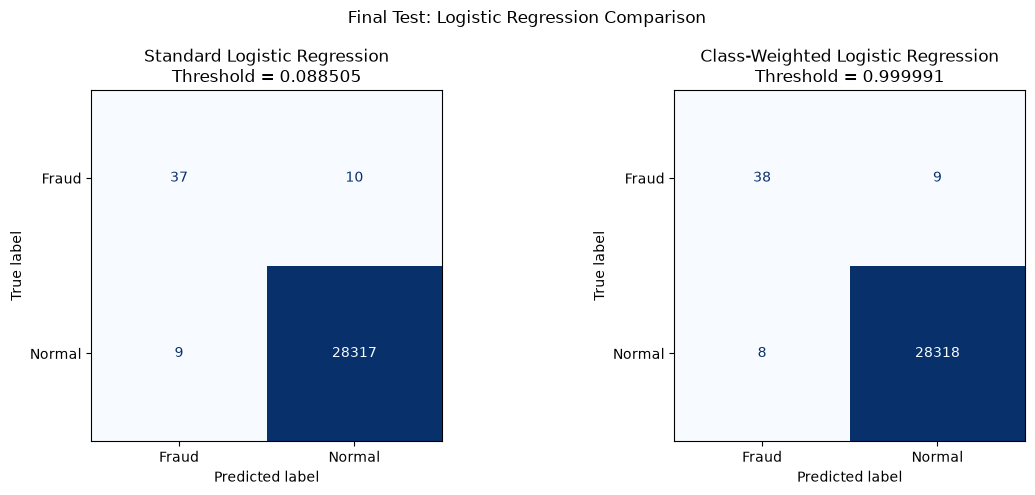

Confusion matrices saved successfully.


In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

figure_dir = Path("../results/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Standard Logistic Regression",
     standard_test_proba, standard_threshold),

    ("Class-Weighted Logistic Regression",
     weighted_test_proba, weighted_threshold)
]

for ax, (name, probabilities, threshold) in zip(axes, models):

    predictions = (probabilities >= threshold).astype(int)

    cm = confusion_matrix(
        y_test, predictions, labels=[1, 0]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Fraud", "Normal"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"{name}\nThreshold = {threshold:.6f}")

fig.suptitle("Final Test: Logistic Regression Comparison")
fig.tight_layout()

# Save before displaying
fig.savefig(
    figure_dir / "07_lr_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")

In [22]:
#Generate Precision-Recall and ROC curves

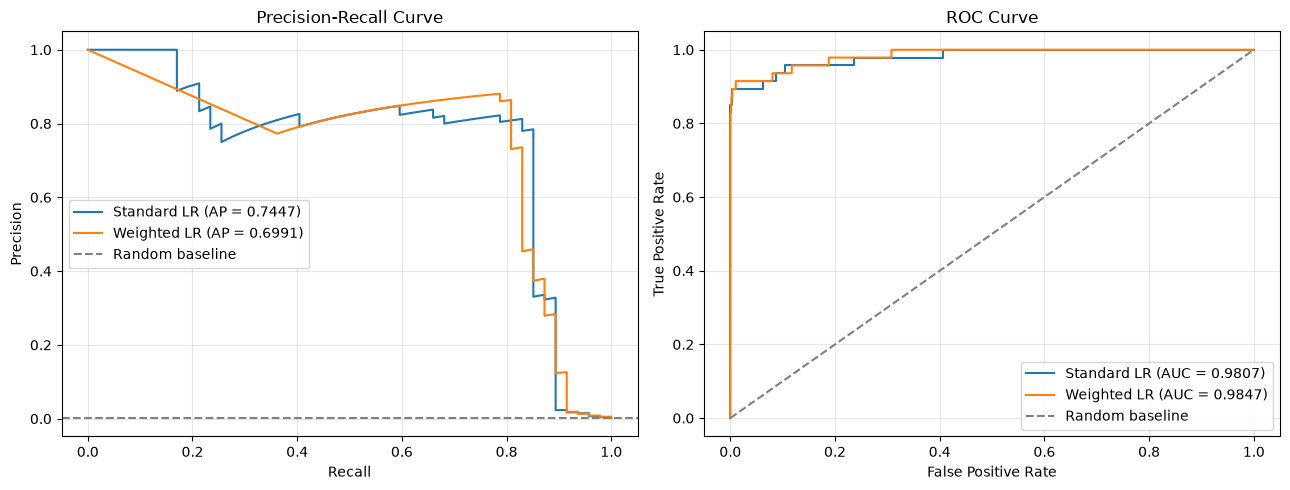

Precision-Recall and ROC curves saved successfully.


In [29]:
from sklearn.metrics import roc_curve, precision_recall_curve

figure_dir = Path("../results/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Standard LR", standard_test_proba),
    ("Weighted LR", weighted_test_proba)
]

for name, probabilities in models:

    # Precision-Recall curve
    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(y_test, probabilities)

    axes[0].plot(
        recall, precision,
        label=f"{name} (AP = {ap:.4f})"
    )

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, probabilities)

    auc = roc_auc_score(y_test, probabilities)

    axes[1].plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

# Random classifier baselines
axes[0].axhline(y_test.mean(), linestyle="--",
                color="gray", label="Random baseline")

axes[1].plot([0, 1], [0, 1], "--",
             color="gray", label="Random baseline")

axes[0].set_title("Precision-Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")

axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()

# Save before displaying
fig.savefig(
    figure_dir / "07_lr_pr_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Precision-Recall and ROC curves saved successfully.")

In [24]:
#Save our experimental results

In [25]:
# Create results directory
output_dir = Path("../results/tables")
output_dir.mkdir(parents=True, exist_ok=True)

# Save validation and test results
validation_results.to_csv(
    output_dir / "07_lr_validation_comparison.csv"
)

test_results.to_csv(
    output_dir / "07_lr_test_comparison.csv"
)

print("Validation and test results saved successfully.")

Validation and test results saved successfully.


In [26]:
figure_dir = Path("../results/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.tight_layout()
plt.savefig(figure_dir / "07_lr_confusion_matrices.png",
            dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [27]:
plt.tight_layout()
plt.savefig(figure_dir / "07_lr_pr_roc_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>